In this tutorial, we will focus on how to detect and visualize the inter-channel PAC modulation via cluster-based permutation testing, and compare it with the regular permutation testing. 


## Permutation testing

Traditional, parametric approaches to statistical testing have revealed unuseful in mass univariate problems due to the Multiple Comparison Problem (MCP). Massive univariate testing yields unnaceptable levels of false significant regions, so a procedure for controlling the problem must be used. Family-wise error rate (FWER) such as the Bonferroni correction arise as overconservative thresholds, proving useless for this purpose. On the other hand, nonparametric approaches have lately gained ground, especially with the emergence of massive computational power.  

Permutation testing approaches have flourished among this plethora of testing methodologies, providing controlled estimation of significance levels at any given $\alpha$ -the statistical significance threshold-. The procedure that underlies this category is the approximation of the nonparametric distribution of the data via the Monte Carlo (MC) method. The simplest approach to permutation testing would work as follows. 

Given a dataset comprising pairs:

$$
(\mathbf{x}_i, y_i), i\in \mathbb{N}
$$

respectively the data and labels of the $i^{th}$ sample, let us call $X$ the matrix containing all data from the $k$ samples: 

$$
X= \{\mathbf{x}_0, \mathbf{x}_1, \dots \mathbf{x}_k\}
$$

and $\mathbf{y}$ the vector containing $k$ labels for each sample. 

Permutation testing works by estimating the empirical quantile by: 

1. First, we compute a statistical on the data using the real $\mathbf{y}$ vector, and save it as the reference $z$. 
2. Define $z_{emp}$ as the empirical quantile reference, as an all-zero vector/array.
3. Generate a surrogate label vector, $\hat{\mathbf{y}}$, and re-estimate the statistical using $\hat{\mathbf{y}}$, which which yields $\hat{z}$.
4. For those features where $\hat{z}>z$, add 1 to $z_{emp}$. 
4. Repeat steps 2-3 surrogate procedure $N$ times
5. The empirical quantile for each feature is $z_{emp}/N$.

## Cluster Based Statistic
Suppose we have 1000 features. If we are performing $N=1000$ iterations over the aforementioned procedure, and checking for significance with $\alpha=0.05$, the probability of a false positive is 5%. Over the 1000 features, there is the possibility of 50 false positives appearing. 

An alternative is to use a multivariate approach. This can be done via a plethora of procedures. However, in this case we are using PAC matrices in which there is a strong dependency in adjacent positions (adjacent frequencies). We can make use of the "clustering" property, in which similar frequency interactions yield similar PAC values, to reduce the number of comparisons. 

To do so, we define the cluster-based statistic. The procedure is similar to the permutation testing approach. However, we will focus on connected clusters instead of individual positions. The algorithm becomes: 

1. First, we compute a statistical on the data using the real $\mathbf{y}$ vector, and save it as the reference $z$. - same as before-. 
2. Threshold $z$ using a conservative statistic. E.g., if using t-test, use a significance level 0.05, and a high number of degrees of freedom. It yields a statistic threshold similar to 1.98. 
3. Once umbralized, $z$ shows a series of connected clusters. Label each of these clusters, and count the number of positions within. Keep only those clusters with more than $c_{th}$ positions. 
4. Compute the Cluster-Based statistic $z_{cb}$, by, e.g. summing all t-values within that cluster. 
5. Define $z_{emp}$ as the empirical quantile reference, as an all-zero vector/array.
6. Generate a surrogate label vector, $\hat{\mathbf{y}}$, and re-estimate the cluster-based statistical using for each cluster, which which yields $\hat{z}_{cb}$.
7. For those clusters where $\hat{z}_{cb}>z_{cb}$, add 1 to the clusters positions in $z_{emp}$. 
8. Repeat steps 6-7 surrogate procedure $N$ times
9. The empirical quantile for each feature is $z_{emp}/N$.

To demonstrate how these two methods work, we will perform a toy example: 

In [36]:
# Imports
import numpy as np
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt 

We are going to generate 30 toy PAC connectivity matrices per group for frequencies `f_pha=(0.5,30)` and `f_amp=(20,100)`, and a coupling frequency between phase of 10 Hz and amplitude of 50 Hz. 

Text(0.5, 1.0, 'Canonical PAC (group 1)')

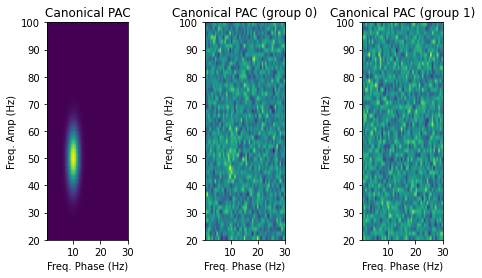

In [37]:
f_pha = np.linspace(0.5,30,50)
f_amp = np.linspace(20,100,50)

coupling_freq = (10, 50) #this is the coupling frequency for phase - amplitude.

xx, yy = np.meshgrid(f_pha, f_amp)
canonical_pac = 50*multivariate_normal.pdf(np.stack((xx, yy), axis=-1), 
                                   mean=coupling_freq, cov=[[2,0.5],[0.2,50]])

# And this is the generator of toy_pacs
def toy_pac(canonical_pac, group=0.):
    toy_pac = (group+np.random.randn(1))*canonical_pac
    toy_pac += .5*np.random.randn(*canonical_pac.shape)
    return toy_pac

# We display the canonical pac
fig, ax = plt.subplots(1, 3, figsize=(8,4))
ax[0].imshow(canonical_pac, origin='lower', 
           extent=(f_pha.min(), f_pha.max(), f_amp.min(), f_amp.max()))
ax[0].set_xlabel('Freq. Phase (Hz)')
ax[0].set_ylabel('Freq. Amp (Hz)')
ax[0].set_title('Canonical PAC')

# generate a toy pac for group 0
ax[1].imshow(toy_pac(canonical_pac, 0), origin='lower', 
           extent=(f_pha.min(), f_pha.max(), f_amp.min(), f_amp.max()))
ax[1].set_xlabel('Freq. Phase (Hz)')
ax[1].set_ylabel('Freq. Amp (Hz)')
ax[1].set_title('Canonical PAC (group 0)')

# generate a toy pac for group 1
ax[2].imshow(toy_pac(canonical_pac, 1), origin='lower', 
           extent=(f_pha.min(), f_pha.max(), f_amp.min(), f_amp.max()))
ax[2].set_xlabel('Freq. Phase (Hz)')
ax[2].set_ylabel('Freq. Amp (Hz)')
ax[2].set_title('Canonical PAC (group 1)')

Now we generate the labels for the 60 subjects, 30 for group 0 and 30 for group 1, and their corresponding pac:

In [38]:
y = np.r_[np.ones(30), np.zeros(30)]
X = np.stack([toy_pac(canonical_pac, group) for group in y])
print(X.shape)

(60, 50, 50)


Let's check what happens with traditional statistical testing. Given our approach, only the cluster should be significant. 

Text(0.5, 1.0, 'p-value < 0.05')

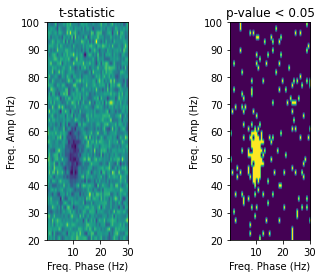

In [39]:
from scipy.stats import ttest_ind

test = ttest_ind
alpha = 0.05 # significance level

raw_test, pval = test(X[y==0],X[y==1])

fig, ax = plt.subplots(1,2)
# generate a toy pac for group 0
ax[0].imshow(raw_test, origin='lower', 
           extent=(f_pha.min(), f_pha.max(), f_amp.min(), f_amp.max()))
ax[0].set_xlabel('Freq. Phase (Hz)')
ax[0].set_ylabel('Freq. Amp (Hz)')
ax[0].set_title('t-statistic')

# generate a toy pac for group 1
ax[1].imshow(pval<alpha, origin='lower', 
           extent=(f_pha.min(), f_pha.max(), f_amp.min(), f_amp.max()))
ax[1].set_xlabel('Freq. Phase (Hz)')
ax[1].set_ylabel('Freq. Amp (Hz)')
ax[1].set_title(f'p-value < {alpha}')


In the regular testing, appart from the original cluster, there appear many spurious areas across all frequencies. If this is the case only for a toy example with gaussian noise, what could not happen to the real case? There, there are many intra and inter-channel couplings, spurious peak, and inter-subject variability. Let's check what happens when we apply permutation testing. 

In [40]:
from functionalpac.statistics import PermutationTesting, ClusterBasedPermutationTesting

n_iter = 1000
output = 'quantile'
cbth = 5
twosided = True

pt = PermutationTesting(n_iter=n_iter, alpha=alpha, test=test, output=output, twosided=twosided)
cbpt = ClusterBasedPermutationTesting(n_iter=n_iter, alpha=alpha, test=test, 
                                      output=output, cluster_threshold=cbth, twosided=twosided)

# Careful with X-shape, wich is expecting (n_subj, n_chan, n_chan, n_pha, n_amp)
res_pt = pt.fit(X.reshape((-1,1,1,len(f_pha), len(f_amp))),y)
res_cb = cbpt.fit(X.reshape((-1,1,1,len(f_pha), len(f_amp))),y)

[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done   2 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done   3 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done   4 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done   5 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done   6 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done   7 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done   8 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done   9 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done  11 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done  12 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done  13 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done  14 tasks      | elapsed:    0.0s
[Parallel(n_jobs=10)]: Done  15 tasks      | elaps

[Parallel(n_jobs=10)]: Done 140 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 141 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 142 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 143 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 144 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 145 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 146 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 147 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 148 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 149 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 150 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 151 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 152 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 153 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 154 tasks      | elapsed:    0.2s
[Parallel(n_jobs=10)]: Done 155 tasks      | elapsed:    0.2s
[Paralle

[Parallel(n_jobs=10)]: Done 283 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 284 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 285 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 286 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 287 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 288 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 289 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 290 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 291 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 292 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 293 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 294 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 295 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 296 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 297 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 298 tasks      | elapsed:    0.4s
[Paralle

[Parallel(n_jobs=10)]: Done 427 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 428 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 429 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 431 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 432 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 433 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 434 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 435 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 436 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 437 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 438 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 439 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 440 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 441 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 442 tasks      | elapsed:    0.6s
[Paralle

[Parallel(n_jobs=10)]: Done 571 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 572 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 573 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 574 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 575 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 576 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 577 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 578 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 579 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 580 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 581 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 582 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 583 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 584 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 585 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 586 tasks      | elapsed:    0.8s
[Paralle

...

[Parallel(n_jobs=10)]: Done 290 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 291 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 292 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 293 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 294 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 295 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 296 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 297 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 298 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 299 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 300 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 301 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 302 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 303 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 304 tasks      | elapsed:    0.4s
[Parallel(n_jobs=10)]: Done 305 tasks      | elapsed:    0.4s
[Paralle

[Parallel(n_jobs=10)]: Done 436 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 437 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 438 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 439 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 440 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 441 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 442 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 443 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 444 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 445 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 446 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 447 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 448 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 449 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 450 tasks      | elapsed:    0.6s
[Parallel(n_jobs=10)]: Done 451 tasks      | elapsed:    0.6s
[Paralle

[Parallel(n_jobs=10)]: Done 576 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 577 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 578 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 579 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 580 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 581 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 582 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 583 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 584 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 585 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 586 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 587 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 588 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 589 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 590 tasks      | elapsed:    0.8s
[Parallel(n_jobs=10)]: Done 591 tasks      | elapsed:    0.8s
[Paralle

[Parallel(n_jobs=10)]: Done 719 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 720 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 721 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 722 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 723 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 724 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 725 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 726 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 727 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 728 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 729 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 730 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 731 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 732 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 733 tasks      | elapsed:    1.0s
[Parallel(n_jobs=10)]: Done 734 tasks      | elapsed:    1.0s
[Paralle

[Parallel(n_jobs=10)]: Done 864 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 865 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 866 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 867 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 868 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 869 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 870 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 871 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 872 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 873 tasks      | elapsed:    1.3s
[Parallel(n_jobs=10)]: Done 874 tasks      | elapsed:    1.3s
[Parallel(n_jobs=10)]: Done 875 tasks      | elapsed:    1.3s
[Parallel(n_jobs=10)]: Done 876 tasks      | elapsed:    1.3s
[Parallel(n_jobs=10)]: Done 877 tasks      | elapsed:    1.3s
[Parallel(n_jobs=10)]: Done 878 tasks      | elapsed:    1.3s
[Parallel(n_jobs=10)]: Done 879 tasks      | elapsed:    1.3s
[Paralle

After performing 1000 iterations, we obtain the results for the regular permutation testing and the cluster-based one: 

Text(0.5, 1.0, 'res_cb < 0.05')

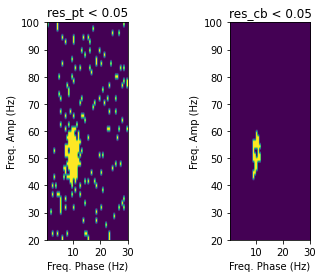

In [41]:
fig, ax = plt.subplots(1,2)
# generate a toy pac for group 0
ax[0].imshow(res_pt[0,0]<alpha, origin='lower', 
           extent=(f_pha.min(), f_pha.max(), f_amp.min(), f_amp.max()))
ax[0].set_xlabel('Freq. Phase (Hz)')
ax[0].set_ylabel('Freq. Amp (Hz)')
ax[0].set_title(f'res_pt < {alpha}')

# generate a toy pac for group 1
ax[1].imshow(res_cb[0,0]<alpha, origin='lower', 
           extent=(f_pha.min(), f_pha.max(), f_amp.min(), f_amp.max()))
ax[1].set_xlabel('Freq. Phase (Hz)')
ax[1].set_ylabel('Freq. Amp (Hz)')
ax[1].set_title(f'res_cb < {alpha}')

As it can be seen, the cluster-based approach is a much more conservative approach. However, it was able to clean all false positive positions and clusters. 